In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import warnings
warnings.filterwarnings('ignore')

print("All imports successful!")

All imports successful!


In [2]:
# Load NABIL data — our best understood stock
df = pd.read_csv('../data/raw/NABIL.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
print(f"Total rows: {len(df)}")
print(f"Date range: {df['Date'].min()} to {df['Date'].max()}")
print(df[['Date', 'Close']].tail(5))

# Prophet requires columns named 'ds' and 'y'
prophet_df = df[['Date', 'Close']].rename(columns={'Date': 'ds', 'Close': 'y'})
print(f"\nProphet dataframe ready!")
print(prophet_df.tail(3))

Total rows: 3476
Date range: 2011-03-20 00:00:00 to 2026-06-25 00:00:00
           Date  Close
3471 2026-06-19  531.0
3472 2026-06-22  531.0
3473 2026-06-23  529.0
3474 2026-06-24  524.5
3475 2026-06-25  521.9

Prophet dataframe ready!
             ds      y
3473 2026-06-23  529.0
3474 2026-06-24  524.5
3475 2026-06-25  521.9


In [3]:
# ── Train Prophet ─────────────────────────────────────────────
model = Prophet(
    daily_seasonality=False,
    weekly_seasonality=True,
    yearly_seasonality=True,
    changepoint_prior_scale=0.05  # controls trend flexibility
)

model.fit(prophet_df)
print("Prophet model trained!")

# ── Forecast next 30 trading days ────────────────────────────
future = model.make_future_dataframe(periods=30, freq='B')  # B = business days
forecast = model.predict(future)

print(f"Forecast shape: {forecast.shape}")
print(f"Forecast columns: {forecast.columns.tolist()}")
print(f"\nNext 5 days forecast:")
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(35).head(5))

19:47:59 - cmdstanpy - INFO - Chain [1] start processing
19:48:01 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained!
Forecast shape: (3505, 19)
Forecast columns: ['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper', 'additive_terms', 'additive_terms_lower', 'additive_terms_upper', 'weekly', 'weekly_lower', 'weekly_upper', 'yearly', 'yearly_lower', 'yearly_upper', 'multiplicative_terms', 'multiplicative_terms_lower', 'multiplicative_terms_upper', 'yhat']

Next 5 days forecast:
             ds        yhat  yhat_lower  yhat_upper
3470 2026-06-19  442.230923  267.681734  616.253561
3471 2026-06-22  489.002913  323.570158  667.618060
3472 2026-06-23  489.859086  324.472814  657.606891
3473 2026-06-24  492.676530  314.278696  668.034870
3474 2026-06-25  492.932715  328.742703  652.249576


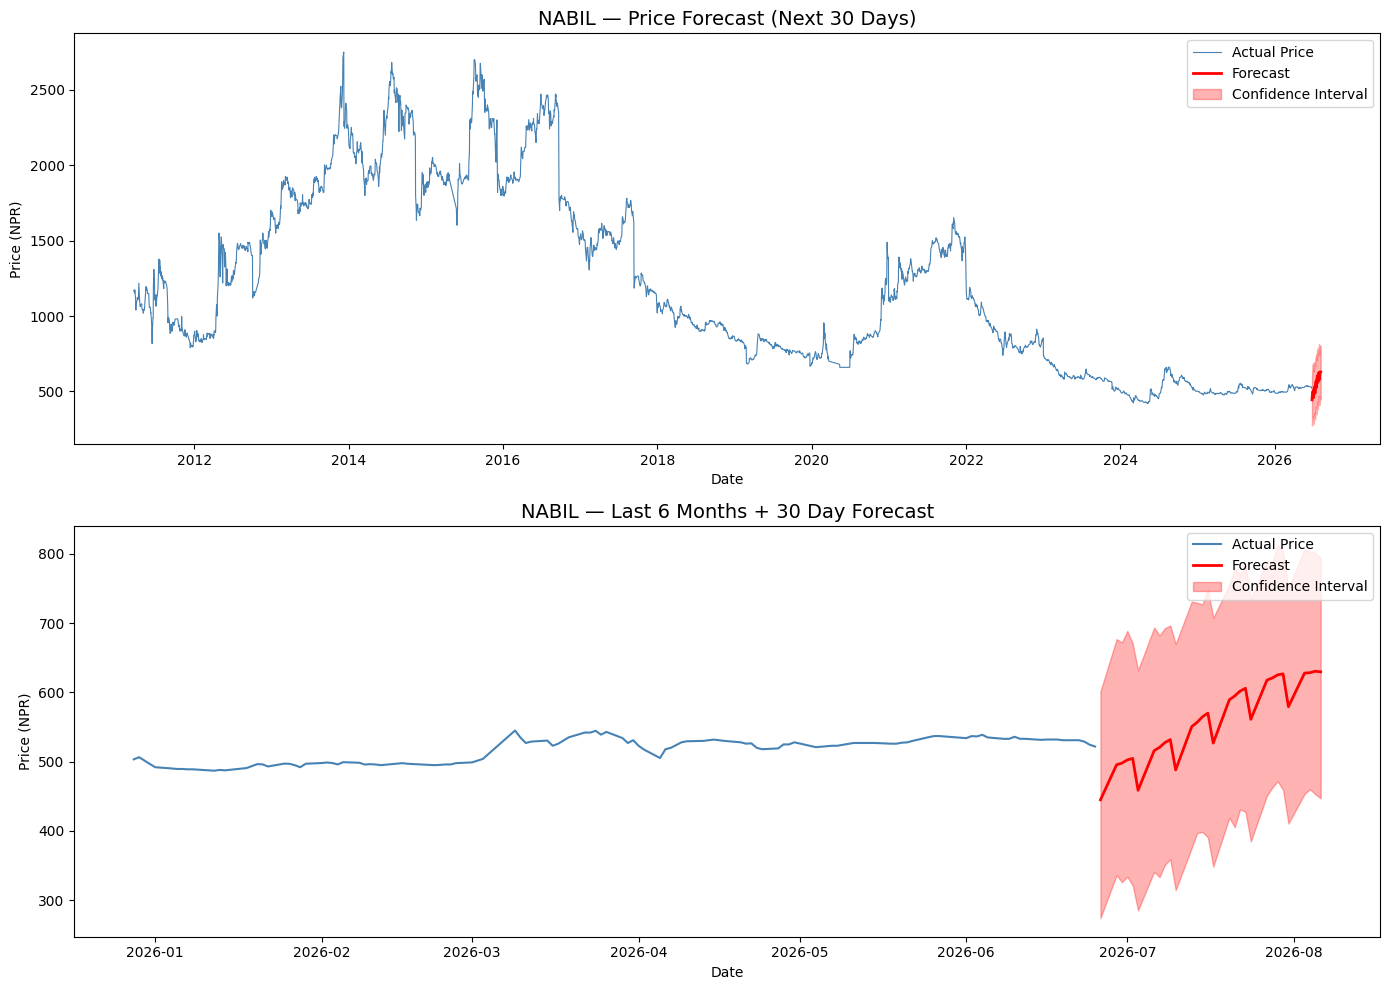


NABIL 30-Day Forecast:
Current Price: NPR 521.9
Forecast (Day 30): NPR 629.7
Lower bound: NPR 447.1
Upper bound: NPR 794.1


In [4]:
# ── Plot forecast ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Plot 1 — Full forecast
ax1 = axes[0]
# Historical data
ax1.plot(prophet_df['ds'], prophet_df['y'], 
         color='steelblue', linewidth=0.8, label='Actual Price')
# Forecast
future_only = forecast[forecast['ds'] > prophet_df['ds'].max()]
ax1.plot(future_only['ds'], future_only['yhat'], 
         color='red', linewidth=2, label='Forecast')
ax1.fill_between(future_only['ds'], 
                 future_only['yhat_lower'], 
                 future_only['yhat_upper'],
                 alpha=0.3, color='red', label='Confidence Interval')
ax1.set_title('NABIL — Price Forecast (Next 30 Days)', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Price (NPR)')
ax1.legend()

# Plot 2 — Last 6 months + forecast
ax2 = axes[1]
cutoff = prophet_df['ds'].max() - pd.Timedelta(days=180)
recent = prophet_df[prophet_df['ds'] >= cutoff]
ax2.plot(recent['ds'], recent['y'],
         color='steelblue', linewidth=1.5, label='Actual Price')
ax2.plot(future_only['ds'], future_only['yhat'],
         color='red', linewidth=2, label='Forecast')
ax2.fill_between(future_only['ds'],
                 future_only['yhat_lower'],
                 future_only['yhat_upper'],
                 alpha=0.3, color='red', label='Confidence Interval')
ax2.set_title('NABIL — Last 6 Months + 30 Day Forecast', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Price (NPR)')
ax2.legend()

plt.tight_layout()
plt.show()

# Print forecast summary
print("\nNABIL 30-Day Forecast:")
print(f"Current Price: NPR {prophet_df['y'].iloc[-1]:.1f}")
print(f"Forecast (Day 30): NPR {future_only['yhat'].iloc[-1]:.1f}")
print(f"Lower bound: NPR {future_only['yhat_lower'].iloc[-1]:.1f}")
print(f"Upper bound: NPR {future_only['yhat_upper'].iloc[-1]:.1f}")

In [6]:
import plotly.graph_objects as go

# Last 6 months + forecast
cutoff = prophet_df['ds'].max() - pd.Timedelta(days=180)
recent = prophet_df[prophet_df['ds'] >= cutoff]
future_only = forecast[forecast['ds'] > prophet_df['ds'].max()]

fig = go.Figure()

# Actual price
fig.add_trace(go.Scatter(
    x=recent['ds'],
    y=recent['y'],
    name='Actual Price',
    line=dict(color='steelblue', width=2),
    hovertemplate='<b>Date:</b> %{x|%Y-%m-%d}<br><b>Price:</b> NPR %{y:.1f}<extra></extra>'
))

# Forecast line
fig.add_trace(go.Scatter(
    x=future_only['ds'],
    y=future_only['yhat'],
    name='Forecast',
    line=dict(color='red', width=2, dash='dash'),
    hovertemplate='<b>Date:</b> %{x|%Y-%m-%d}<br><b>Forecast:</b> NPR %{y:.1f}<extra></extra>'
))

# Upper bound
fig.add_trace(go.Scatter(
    x=future_only['ds'],
    y=future_only['yhat_upper'],
    name='Upper Bound',
    line=dict(width=0),
    showlegend=False,
    hovertemplate='<b>Upper:</b> NPR %{y:.1f}<extra></extra>'
))

# Lower bound with fill
fig.add_trace(go.Scatter(
    x=future_only['ds'],
    y=future_only['yhat_lower'],
    name='Confidence Interval',
    line=dict(width=0),
    fill='tonexty',
    fillcolor='rgba(255,0,0,0.15)',
    hovertemplate='<b>Lower:</b> NPR %{y:.1f}<extra></extra>'
))

fig.update_layout(
    title='NABIL — Last 6 Months + 30 Day Forecast',
    xaxis_title='Date',
    yaxis_title='Price (NPR)',
    hovermode='x unified',
    template='plotly_white',
    height=500,
    legend=dict(orientation='h', yanchor='bottom', y=1.02),

    # ── Zoom controls ─────────────────────────────────────────
    xaxis=dict(
        rangeslider=dict(visible=True),  # slider at bottom
        rangeselector=dict(             # quick zoom buttons
            buttons=list([
                dict(count=7,  label='1W', step='day',  stepmode='backward'),
                dict(count=1,  label='1M', step='month', stepmode='backward'),
                dict(count=3,  label='3M', step='month', stepmode='backward'),
                dict(count=6,  label='6M', step='month', stepmode='backward'),
                dict(step='all', label='All')
            ])
        )
    )
)

fig.show()

print(f"\nCurrent Price: NPR {prophet_df['y'].iloc[-1]:.1f}")
print(f"30-Day Forecast: NPR {future_only['yhat'].iloc[-1]:.1f}")
print(f"Range: NPR {future_only['yhat_lower'].iloc[-1]:.1f} - NPR {future_only['yhat_upper'].iloc[-1]:.1f}")


Current Price: NPR 521.9
30-Day Forecast: NPR 629.7
Range: NPR 447.1 - NPR 794.1


In [7]:
# Show what Prophet learned — trend, weekly, yearly patterns
fig2 = go.Figure()

# Trend component
fig2.add_trace(go.Scatter(
    x=forecast['ds'],
    y=forecast['trend'],
    name='Trend',
    line=dict(color='steelblue', width=2),
    hovertemplate='<b>Date:</b> %{x|%Y-%m-%d}<br><b>Trend:</b> NPR %{y:.1f}<extra></extra>'
))

fig2.update_layout(
    title='NABIL — Long Term Price Trend',
    xaxis_title='Date',
    yaxis_title='Price (NPR)',
    hovermode='x unified',
    template='plotly_white',
    height=400,
    xaxis=dict(
        rangeslider=dict(visible=True),
        rangeselector=dict(
            buttons=list([
                dict(count=1,  label='1Y',  step='year',  stepmode='backward'),
                dict(count=3,  label='3Y',  step='year',  stepmode='backward'),
                dict(count=5,  label='5Y',  step='year',  stepmode='backward'),
                dict(step='all', label='All')
            ])
        )
    )
)

fig2.show()